**Data Cleaning and Preparation
Problem Statement: Analyzing Customer Churn in a Telecommunications Company
Dataset: "Telecom_Customer_Churn.csv"
Description: The dataset contains information about customers of a telecommunications
company and whether they have churned (i.e., discontinued their services). The dataset
includes various attributes of the customers, such as their demographics, usage patterns, and
account information. The goal is to perform data cleaning and preparation to gain insights
into the factors that contribute to customer churn.
Tasks to Perform:
1. Import the "Telecom_Customer_Churn.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Handle missing values in the dataset, deciding on an appropriate strategy.
4. Remove any duplicate records from the dataset.
5. Check for inconsistent data, such as inconsistent formatting or spelling variations,
and standardize it.
6. Convert columns to the correct data types as needed.
7. Identify and handle outliers in the data.
8. Perform feature engineering, creating new features that may be relevant to
predicting customer churn.
9. Normalize or scale the data if necessary.
10. Split the dataset into training and testing sets for further analysis.
11. Export the cleaned dataset for future analysis or modeling.**

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv('Telecom_Customer_Churn.csv')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7043
Columns: 21


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [10]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [11]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [13]:
df = df.replace(r'^\s*$', np.nan, regex=True)

In [14]:
if 'TotalCharges' in df.columns:
    df['TotalCharges'] = pd.to_numeric(
        df['TotalCharges'],
        errors='coerce'
    )

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [15]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print("Numerical missing values handled!")

Numerical missing values handled!


In [16]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Categorical missing values handled!")

Categorical missing values handled!


C:\Users\Admin\AppData\Local\Temp\ipykernel_10148\631873206.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [17]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [18]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


In [19]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

print("Extra spaces removed!")

Extra spaces removed!


C:\Users\Admin\AppData\Local\Temp\ipykernel_10148\2689342618.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [20]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.title()

df.head()

C:\Users\Admin\AppData\Local\Temp\ipykernel_10148\3632465755.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-Vhveg,Female,0,Yes,No,1,No,No Phone Service,Dsl,No,...,No,No,No,No,Month-To-Month,Yes,Electronic Check,29.85,29.85,No
1,5575-Gnvde,Male,0,No,No,34,Yes,No,Dsl,Yes,...,Yes,No,No,No,One Year,No,Mailed Check,56.95,1889.50,No
2,3668-Qpybk,Male,0,No,No,2,Yes,No,Dsl,Yes,...,No,No,No,No,Month-To-Month,Yes,Mailed Check,53.85,108.15,Yes
3,7795-Cfocw,Male,0,No,No,45,No,No Phone Service,Dsl,Yes,...,Yes,Yes,No,No,One Year,No,Bank Transfer (Automatic),42.30,1840.75,No
4,9237-Hqitu,Female,0,No,No,2,Yes,No,Fiber Optic,No,...,No,No,No,No,Month-To-Month,Yes,Electronic Check,70.70,151.65,Yes


In [21]:
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


In [22]:
if 'SeniorCitizen' in df.columns:
    df['SeniorCitizen'] = df['SeniorCitizen'].astype(int)

if 'tenure' in df.columns:
    df['tenure'] = df['tenure'].astype(int)

if 'MonthlyCharges' in df.columns:
    df['MonthlyCharges'] = df['MonthlyCharges'].astype(float)

if 'TotalCharges' in df.columns:
    df['TotalCharges'] = df['TotalCharges'].astype(float)

print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object


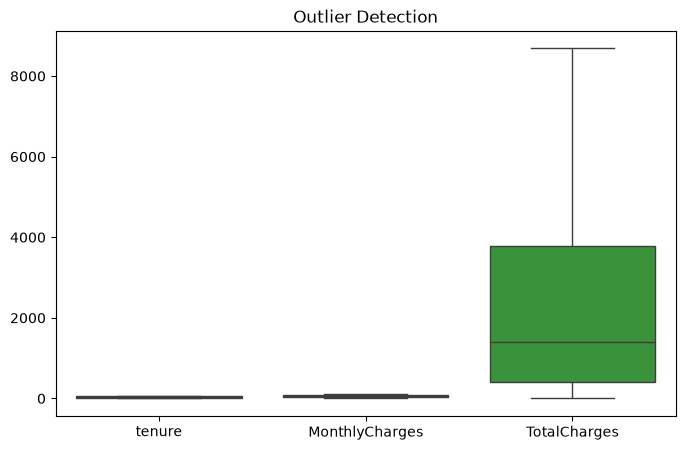

In [24]:
#identifying and handling outliers
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[['tenure', 'MonthlyCharges', 'TotalCharges']])

plt.title('Outlier Detection')
plt.show()

In [25]:
outlier_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in outlier_cols:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df[col] = df[col].clip(lower, upper)

print("Outliers handled successfully!")

Outliers handled successfully!


In [26]:
#feature engineering
if 'tenure' in df.columns:
    df['Tenure_Group'] = pd.cut(
        df['tenure'],
        bins=[-1, 12, 24, 48, 72],
        labels=['New', 'Medium', 'Long', 'Very Long']
    )

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_Group
0,7590-Vhveg,Female,0,Yes,No,1,No,No Phone Service,Dsl,No,...,No,No,No,Month-To-Month,Yes,Electronic Check,29.85,29.85,No,New
1,5575-Gnvde,Male,0,No,No,34,Yes,No,Dsl,Yes,...,No,No,No,One Year,No,Mailed Check,56.95,1889.50,No,Long
2,3668-Qpybk,Male,0,No,No,2,Yes,No,Dsl,Yes,...,No,No,No,Month-To-Month,Yes,Mailed Check,53.85,108.15,Yes,New
3,7795-Cfocw,Male,0,No,No,45,No,No Phone Service,Dsl,Yes,...,Yes,No,No,One Year,No,Bank Transfer (Automatic),42.30,1840.75,No,Long
4,9237-Hqitu,Female,0,No,No,2,Yes,No,Fiber Optic,No,...,No,No,No,Month-To-Month,Yes,Electronic Check,70.70,151.65,Yes,New


In [27]:
#total services used by the user

service_cols = [
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

available_services = [
    col for col in service_cols if col in df.columns
]

df['Total_Services'] = df[available_services].apply(
    lambda row: sum(
        value not in ['No', 'No internet service',
                      'No phone service', 'Not Applicable']
        for value in row
    ),
    axis=1
)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_Group,Total_Services
0,7590-Vhveg,Female,0,Yes,No,1,No,No Phone Service,Dsl,No,...,No,No,Month-To-Month,Yes,Electronic Check,29.85,29.85,No,New,2
1,5575-Gnvde,Male,0,No,No,34,Yes,No,Dsl,Yes,...,No,No,One Year,No,Mailed Check,56.95,1889.50,No,Long,3
2,3668-Qpybk,Male,0,No,No,2,Yes,No,Dsl,Yes,...,No,No,Month-To-Month,Yes,Mailed Check,53.85,108.15,Yes,New,3
3,7795-Cfocw,Male,0,No,No,45,No,No Phone Service,Dsl,Yes,...,No,No,One Year,No,Bank Transfer (Automatic),42.30,1840.75,No,Long,4
4,9237-Hqitu,Female,0,No,No,2,Yes,No,Fiber Optic,No,...,No,No,Month-To-Month,Yes,Electronic Check,70.70,151.65,Yes,New,1


In [28]:
#Customers are categorized according to their monthly charges
if 'MonthlyCharges' in df.columns:
    df['Charge_Category'] = pd.cut(
        df['MonthlyCharges'],
        bins=[-1, 35, 70, float('inf')],
        labels=['Low', 'Medium', 'High']
    )

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_Group,Total_Services,Charge_Category
0,7590-Vhveg,Female,0,Yes,No,1,No,No Phone Service,Dsl,No,...,No,Month-To-Month,Yes,Electronic Check,29.85,29.85,No,New,2,Low
1,5575-Gnvde,Male,0,No,No,34,Yes,No,Dsl,Yes,...,No,One Year,No,Mailed Check,56.95,1889.50,No,Long,3,Medium
2,3668-Qpybk,Male,0,No,No,2,Yes,No,Dsl,Yes,...,No,Month-To-Month,Yes,Mailed Check,53.85,108.15,Yes,New,3,Medium
3,7795-Cfocw,Male,0,No,No,45,No,No Phone Service,Dsl,Yes,...,No,One Year,No,Bank Transfer (Automatic),42.30,1840.75,No,Long,4,Medium
4,9237-Hqitu,Female,0,No,No,2,Yes,No,Fiber Optic,No,...,No,Month-To-Month,Yes,Electronic Check,70.70,151.65,Yes,New,1,High


In [29]:
if 'Churn' not in df.columns:
    raise ValueError("Churn target column not found!")

print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [30]:
#converting churn into numeric values

df['Churn'] = df['Churn'].astype(str).str.strip().str.title()

df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

df = df.dropna(subset=['Churn'])

df['Churn'] = df['Churn'].astype(int)

df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [31]:
#spliting data
X = df.drop(columns=['Churn'])

y = df['Churn']

# Remove customer ID because it is only an identifier
if 'customerID' in X.columns:
    X = X.drop(columns=['customerID'])

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 22)
Target: (7043,)


In [32]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 22)
Testing data: (1409, 22)


In [33]:
#encode categorical columns
X_train = pd.get_dummies(X_train, drop_first=True)

X_test = pd.get_dummies(X_test, drop_first=True)

# Ensure both datasets have the same columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5634, 36)
Testing shape: (1409, 36)


In [34]:
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Feature scaling completed!")

Feature scaling completed!


In [35]:
df.to_csv('cleaned_telecom_churn.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [36]:
X_train.to_csv('X_train.csv', index=False)
X_test.to_csv('X_test.csv', index=False)

y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print("Training and testing datasets exported!")

Training and testing datasets exported!


In [37]:
print("========== FINAL DATASET REPORT ==========")

print("Original cleaned dataset:", df.shape)

print("Training features:", X_train.shape)

print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)

print("Testing target:", y_test.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nChurn Distribution:")
print(df['Churn'].value_counts())

========== FINAL DATASET REPORT ==========
Original cleaned dataset: (7043, 24)
Training features: (5634, 36)
Testing features: (1409, 36)
Training target: (5634,)
Testing target: (1409,)

Missing Values:
0

Duplicate Records:
0

Churn Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
